# Лабораторная работа 2. <br/> Методы решения нелинейных уравнений и систем нелинейных уравнений


## Общий функционал


In [1]:
import math

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


In [2]:
def fmt(value):
    return f"{value:.12g}" if isinstance(value, float) else str(value)


def print_table(headers, rows):
    rows = [[fmt(value) for value in row] for row in rows]
    widths = [max(len(str(header)), *(len(row[i]) for row in rows))
              for i, header in enumerate(headers)]

    def line(row):
        return " | ".join(str(value).rjust(width) for value, width in zip(row, widths))

    print(line(headers))
    print("-+-".join("-" * width for width in widths))
    for row in rows:
        print(line(row))


def sample_points(left, right, count):
    return [left + (right - left) * i / (count - 1) for i in range(count)]


def norm_inf(values):
    """Максимальная норма вектора, используемая в примерах §2.2."""
    return max(abs(value) for value in values)


## Задание 2.1. Решение нелинейных уравнений

### Условие

Реализовать методы простой итерации и Ньютона решения нелинейных уравнений
в виде программ, задавая в качестве входных данных точность вычислений.
С использованием разработанного программного обеспечения
найти положительный корень нелинейного уравнения
(начальное приближение определить графически).
Проанализировать зависимость погрешности вычислений от количества итераций.


### Входные данные

$\sqrt{1 - x^2} - e^x + 0,1 = 0$


In [3]:
data1 = {
    "epsilon": 1e-8,
    "x0": 0.1,
    "c": 0.1,
    "interval": (0.0, 0.1),
    "plot_interval": (0.0, 0.99),
    "max_iterations": 1000,
}


### Реализация

Простая итерация (2.6), оценка погрешности (2.7), метод Ньютона (2.2).


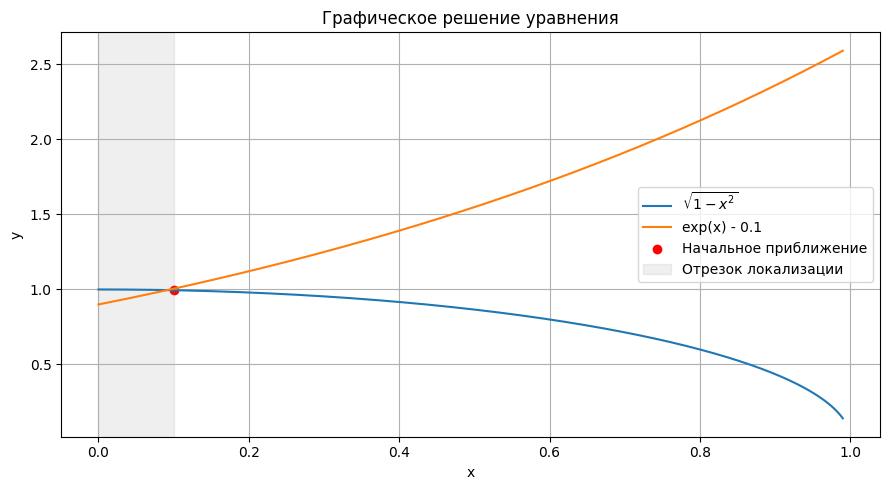

Точность: 1e-08; начальное приближение: 0.1
Отрезок локализации: [0, 0.1]

Величины для обоснования сходимости:
                      Величина |        Значение
-------------------------------+----------------
                          f(a) |             0.1
                          f(b) | -0.010183480969
 phi(b), нижняя граница образа | 0.0907428902407
phi(a), верхняя граница образа | 0.0953101798043
             q = max |phi'(x)| | 0.0917853284157
               f(x0) * f''(x0) | 0.0215926521278

Метод простой итерации, формулы (2.6), (2.7):
k |            x(k) |       Модуль шага |           Невязка |   Оценка по (2.7)
--+-----------------+-------------------+-------------------+------------------
1 | 0.0907428902407 |  0.00925710975934 | 0.000886916349062 | 0.000935535271589
2 | 0.0915525409465 | 0.000809650705793 | 7.41062945111e-05 |  8.1824328827e-05
3 | 0.0914849156753 | 6.76252711224e-05 | 6.21506122236e-06 | 6.83429580403e-06
4 | 0.0914905873692 | 5.67169391821e-06 | 5.21075

In [4]:
# Исходное уравнение и преобразование для простой итерации.
def f_scalar(x, c):
    return math.sqrt(1 - x ** 2) - math.exp(x) + c


def phi_scalar(x, c):
    return math.log(math.sqrt(1 - x ** 2) + c)


def df_scalar(x, c):
    return -x / math.sqrt(1 - x ** 2) - math.exp(x)


def ddf_scalar(x, c):
    return -(1 - x ** 2) ** (-1.5) - math.exp(x)


def dphi_scalar(x, c):
    s = math.sqrt(1 - x ** 2)
    return -x / (s * (s + c))


def simple_iteration_scalar(f, phi, x0, epsilon, q, max_iterations):
    x = x0
    history = []

    for k in range(1, max_iterations + 1):
        x_next = phi(x)
        difference = abs(x_next - x)
        residual = abs(f(x_next))
        # Апостериорная оценка погрешности по формуле (2.7).
        error_bound = q / (1 - q) * difference
        history.append((k, x_next, difference, residual, error_bound))

        if error_bound <= epsilon:
            return x_next, history

        x = x_next

    raise RuntimeError("Метод простой итерации не достиг заданной точности")


def newton_scalar(f, df, x0, epsilon, max_iterations):
    x = x0
    history = []

    for k in range(1, max_iterations + 1):
        # Итерационная формула Ньютона (2.2).
        x_next = x - f(x) / df(x)
        difference = abs(x_next - x)
        residual = abs(f(x_next))
        history.append((k, x_next, difference, residual))

        # Практический критерий остановки из §2.1.
        if difference < epsilon:
            return x_next, history

        x = x_next

    raise RuntimeError("Метод Ньютона не достиг заданной точности")


def main(data):
    epsilon = data["epsilon"]
    x0 = data["x0"]
    c = data["c"]
    left, right = data["interval"]
    max_iterations = data["max_iterations"]
    f = lambda x: f_scalar(x, c)
    phi = lambda x: phi_scalar(x, c)
    df = lambda x: df_scalar(x, c)

    # На выбранном неотрицательном отрезке |phi'(x)| возрастает.
    # Поэтому максимум в условии теоремы 2.3 достигается справа.
    q = abs(dphi_scalar(right, c))
    image = (phi(right), phi(left))

    # Графическое отделение корня, как в §2.1.
    grid = sample_points(*data["plot_interval"], count=991)
    _, axis = plt.subplots(figsize=(9, 5))
    axis.plot(grid, [math.sqrt(1 - x ** 2) for x in grid], label=r"$\sqrt{1-x^2}$")
    axis.plot(grid, [math.exp(x) - c for x in grid], label=f"exp(x) - {c:g}")
    axis.scatter([x0], [math.sqrt(1 - x0 ** 2)], color="red", label="Начальное приближение")
    axis.axvspan(left, right, color="gray", alpha=0.12, label="Отрезок локализации")
    axis.set(xlabel="x", ylabel="y", title="Графическое решение уравнения")
    axis.grid(True)
    axis.legend()
    axis.figure.tight_layout()
    plt.show()

    print(f"Точность: {epsilon:g}; начальное приближение: {x0:g}")
    print(f"Отрезок локализации: [{left:g}, {right:g}]")
    print("\nВеличины для обоснования сходимости:")
    print_table(["Величина", "Значение"], [
        ("f(a)", f(left)),
        ("f(b)", f(right)),
        ("phi(b), нижняя граница образа", image[0]),
        ("phi(a), верхняя граница образа", image[1]),
        ("q = max |phi'(x)|", q),
        ("f(x0) * f''(x0)", f(x0) * ddf_scalar(x0, c)),
    ])

    simple_root, simple_history = simple_iteration_scalar(f, phi, x0, epsilon, q, max_iterations)
    newton_root, newton_history = newton_scalar(f, df, x0, epsilon, max_iterations)

    print("\nМетод простой итерации, формулы (2.6), (2.7):")
    print_table(["k", "x(k)", "Модуль шага", "Невязка", "Оценка по (2.7)"], simple_history)
    print("\nМетод Ньютона, формула (2.2):")
    print_table(["k", "x(k)", "Модуль шага", "Невязка"], newton_history)
    print("\nСравнение методов:")
    print_table(["Метод", "Корень", "Итераций", "Модуль последнего шага", "Невязка", "Оценка (2.7)"], [
        ("Простая итерация", simple_root, len(simple_history), *simple_history[-1][2:]),
        ("Ньютон", newton_root, len(newton_history), *newton_history[-1][2:], "—"),
    ])
    print(f"Разность полученных корней: {abs(simple_root - newton_root):.3e}")
    return {"q": q, "simple": (simple_root, simple_history), "newton": (newton_root, newton_history)}


result1 = main(data1)


## Задание 2.2. Решение систем нелинейных уравнений

### Условие

Реализовать методы простой итерации и Ньютона решения систем нелинейных уравнений
в виде программного кода, задавая в качестве входных данных точность вычислений.
С использованием разработанного программного обеспечения
решить систему нелинейных уравнений (при наличии нескольких решений
найти то из них, в котором значения неизвестных являются положительными);
начальное приближение определить графически.
Проанализировать зависимость погрешности вычислений от количества итераций.


### Входные данные

Значение параметра $a = 4$.

$\begin{cases} (x_1^2 + a^2)x_2 - a^3 = 0 \\ (x_1 - a/2)^2 + (x_2 - a/2)^2 - a^2 = 0 \end{cases}$


In [5]:
data2 = {
    "epsilon": 1e-8,
    "a": 4.0,
    "x0": 6.0,
    "y0": 1.0,
    "x_interval": (5.8, 6.0),
    "y_interval": (1.0, 1.4),
    "plot_x_interval": (0.0, 8.0),
    "plot_y_interval": (0.0, 4.0),
    "max_iterations": 1000,
}


### Реализация

Простая итерация (2.23), оценка погрешности (2.26), метод Ньютона (2.15), (2.16), критерий (2.18).


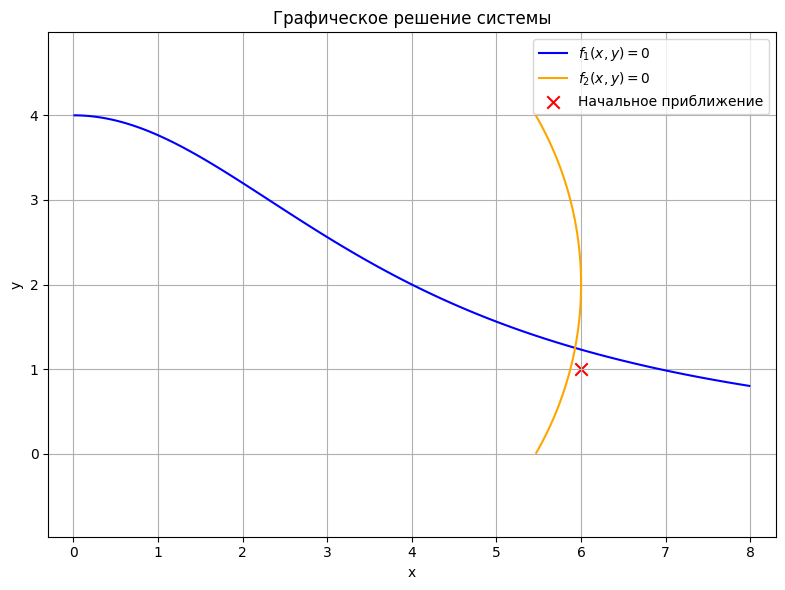

Параметр a = 4; точность: 1e-08
Начальное приближение: (6, 1)
Область G: [5.8, 6] x [1, 1.4]
Во всех таблицах используется максимальная норма.

Величины для обоснования сходимости:
                         Величина |       Значение
----------------------------------+---------------
Максимум суммы модулей в строке 1 | 0.258198889747
Максимум суммы модулей в строке 2 | 0.301282854603
              q, оценка по (2.27) | 0.301282854603
                 Минимум phi1 в G |  5.87298334621
                Максимум phi1 в G |  5.95474398666
                 Минимум phi2 в G |  1.23076923077
                Максимум phi2 в G |  1.28928283642

Метод простой итерации, формулы (2.23), (2.26):
 k |          x(k) |          y(k) |        Норма шага |           Невязка |  Оценка по (2.26)
---+---------------+---------------+-------------------+-------------------+------------------
 1 | 5.87298334621 | 1.23076923077 |    0.230769230769 |      1.8560819879 |   0.0995063783088
 2 | 5.92533871451 | 1.267

In [6]:
# Исходная система и преобразование для простой итерации.
def f1(x, y, a):
    return (x ** 2 + a ** 2) * y - a ** 3


def f2(x, y, a):
    return (x - a / 2) ** 2 + (y - a / 2) ** 2 - a ** 2


def phi1(x, y, a):
    return a / 2 + math.sqrt(a ** 2 - (y - a / 2) ** 2)


def phi2(x, y, a):
    return a ** 3 / (x ** 2 + a ** 2)


def jacobian(x, y, a):
    return [
        [2 * x * y, x ** 2 + a ** 2],
        [2 * (x - a / 2), 2 * (y - a / 2)],
    ]


def solve_linear_system(A, b):
    """Собственное решение системы 2x2 методом Крамера."""
    determinant = A[0][0] * A[1][1] - A[0][1] * A[1][0]
    dx = (b[0] * A[1][1] - A[0][1] * b[1]) / determinant
    dy = (A[0][0] * b[1] - b[0] * A[1][0]) / determinant
    return dx, dy


def contraction_system(a, x_interval, y_interval):
    """Максимум суммы модулей производных в строке: формулы (2.25), (2.27)."""
    xl, xr = x_interval
    yl, yr = y_interval
    max_shift = max(abs(yl - a / 2), abs(yr - a / 2))
    first_row = max_shift / math.sqrt(a ** 2 - max_shift ** 2)

    # Для |d phi2 / dx| достаточно концов отрезка и стационарных точек.
    candidates = [xl, xr]
    for point in (-abs(a) / math.sqrt(3), abs(a) / math.sqrt(3)):
        if xl <= point <= xr:
            candidates.append(point)
    second_row = max(abs(-2 * a ** 3 * x / (x ** 2 + a ** 2) ** 2) for x in candidates)

    # Образ прямоугольника G: экстремумы phi1 по y, phi2 по x.
    y_candidates = [yl, yr]
    if yl <= a / 2 <= yr:
        y_candidates.append(a / 2)
    x_candidates = [xl, xr]
    if xl <= 0 <= xr:
        x_candidates.append(0)
    image_x = [phi1(xl, y, a) for y in y_candidates]
    image_y = [phi2(x, yl, a) for x in x_candidates]
    return max(first_row, second_row), (first_row, second_row), (min(image_x), max(image_x)), (min(image_y), max(image_y))


def simple_iteration_system(f1, f2, phi1, phi2, x0, y0, epsilon, q, max_iterations):
    x, y = x0, y0
    history = []

    for k in range(1, max_iterations + 1):
        # Обе координаты берутся с предыдущей итерации, как в (2.23).
        x_next = phi1(x, y)
        y_next = phi2(x, y)
        difference = norm_inf((x_next - x, y_next - y))
        residual = norm_inf((f1(x_next, y_next), f2(x_next, y_next)))
        error_bound = q / (1 - q) * difference
        history.append((k, x_next, y_next, difference, residual, error_bound))

        if error_bound <= epsilon:
            return x_next, y_next, history

        x, y = x_next, y_next

    raise RuntimeError("Метод простой итерации не достиг заданной точности")


def newton_system(f1, f2, J, x0, y0, epsilon, max_iterations):
    x, y = x0, y0
    history = []

    for k in range(1, max_iterations + 1):
        # J * delta = -F, затем x_next = x + delta: (2.15), (2.16).
        matrix = J(x, y)
        rhs = [-f1(x, y), -f2(x, y)]
        dx, dy = solve_linear_system(matrix, rhs)
        x_next = x + dx
        y_next = y + dy
        difference = norm_inf((dx, dy))
        residual = norm_inf((f1(x_next, y_next), f2(x_next, y_next)))
        history.append((k, x_next, y_next, difference, residual))

        # Критерий (2.18) в максимальной норме, как в примере методички.
        if difference <= epsilon:
            return x_next, y_next, history

        x, y = x_next, y_next

    raise RuntimeError("Метод Ньютона не достиг заданной точности")


def main(data):
    epsilon = data["epsilon"]
    x0, y0 = data["x0"], data["y0"]
    a = data["a"]
    x_interval, y_interval = data["x_interval"], data["y_interval"]
    max_iterations = data["max_iterations"]
    first = lambda x, y: f1(x, y, a)
    second = lambda x, y: f2(x, y, a)
    first_phi = lambda x, y: phi1(x, y, a)
    second_phi = lambda x, y: phi2(x, y, a)
    J = lambda x, y: jacobian(x, y, a)
    q, row_bounds, image_x, image_y = contraction_system(a, x_interval, y_interval)

    # Кривые f1 = 0 и f2 = 0 определяют область положительного решения.
    grid_x = sample_points(*data["plot_x_interval"], count=401)
    grid_y = sample_points(*data["plot_y_interval"], count=201)
    values1 = [[first(x, y) for x in grid_x] for y in grid_y]
    values2 = [[second(x, y) for x in grid_x] for y in grid_y]
    _, axis = plt.subplots(figsize=(8, 6))
    axis.contour(grid_x, grid_y, values1, levels=[0], colors="blue")
    axis.contour(grid_x, grid_y, values2, levels=[0], colors="orange")
    initial = axis.scatter([x0], [y0], color="red", marker="x", s=80, label="Начальное приближение")
    # Явные объекты легенды связывают каждую подпись с правильным цветом.
    axis.legend(handles=[
        Line2D([], [], color="blue", label=r"$f_1(x,y)=0$"),
        Line2D([], [], color="orange", label=r"$f_2(x,y)=0$"),
        initial,
    ])
    axis.set(xlabel="x", ylabel="y", title="Графическое решение системы")
    axis.grid(True)
    axis.axis("equal")
    axis.figure.tight_layout()
    plt.show()

    print(f"Параметр a = {a:g}; точность: {epsilon:g}")
    print(f"Начальное приближение: ({x0:g}, {y0:g})")
    print(f"Область G: [{x_interval[0]:g}, {x_interval[1]:g}] x [{y_interval[0]:g}, {y_interval[1]:g}]")
    print("Во всех таблицах используется максимальная норма.")
    print("\nВеличины для обоснования сходимости:")
    print_table(["Величина", "Значение"], [
        ("Максимум суммы модулей в строке 1", row_bounds[0]),
        ("Максимум суммы модулей в строке 2", row_bounds[1]),
        ("q, оценка по (2.27)", q),
        ("Минимум phi1 в G", image_x[0]),
        ("Максимум phi1 в G", image_x[1]),
        ("Минимум phi2 в G", image_y[0]),
        ("Максимум phi2 в G", image_y[1]),
    ])

    simple_x, simple_y, simple_history = simple_iteration_system(
        first, second, first_phi, second_phi, x0, y0, epsilon, q, max_iterations)
    newton_x, newton_y, newton_history = newton_system(
        first, second, J, x0, y0, epsilon, max_iterations)

    print("\nМетод простой итерации, формулы (2.23), (2.26):")
    print_table(["k", "x(k)", "y(k)", "Норма шага", "Невязка", "Оценка по (2.26)"], simple_history)
    print("\nМетод Ньютона, формулы (2.15), (2.16), (2.18):")
    print_table(["k", "x(k)", "y(k)", "Норма шага", "Невязка"], newton_history)
    print("\nСравнение методов:")
    print_table(["Метод", "x", "y", "Итераций", "Норма последнего шага", "Невязка", "Оценка (2.26)"], [
        ("Простая итерация", simple_x, simple_y, len(simple_history), *simple_history[-1][3:]),
        ("Ньютон", newton_x, newton_y, len(newton_history), *newton_history[-1][3:], "—"),
    ])
    distance = norm_inf((simple_x - newton_x, simple_y - newton_y))
    print(f"Норма разности полученных решений: {distance:.3e}")
    return {"q": q, "simple": ((simple_x, simple_y), simple_history),
            "newton": ((newton_x, newton_y), newton_history)}


result2 = main(data2)
